## read_data

In [1]:
#| default_exp dataload

In [2]:
#| export

import numpy as np
from astropy.io import fits
from astropy.time import Time
MAS2RAD = 4.8481368e-9
SPEEDOFLIGHT = 299792458.0

def read_data(ifile):
    
    """
    Reads interferometric data from an OIFITS file and extracts relevant observables.

    Parameters
    ----------
    ifile : str
        Path to the OIFITS file.

    Returns
    -------
    data_dict : dict
        Dictionary containing extracted information:
            
    """
    
    with fits.open(ifile) as ff:
        nlam = len(ff['OI_WAVELENGTH'].data['EFF_WAVE'])  # Number of wavelength channels
        nbl  = len(ff['OI_VIS'].data['UCOORD'])          # Number of baselines
        ncl  = len(ff['OI_T3'].data['TIME'])  
        
        nframe = 0
        for tab in ff[1:]:
            nframe += tab.header['EXTNAME']=='OI_VIS'
        
        
    # Initialize data arrays
    phi    = np.full((nframe, nbl, nlam), np.nan)
    rho    = np.full((nframe, nbl, nlam), np.nan)
    phie   = np.full((nframe, nbl, nlam), np.nan)
    rhoe   = np.full((nframe, nbl, nlam), np.nan)
    vis2   = np.full((nframe, nbl, nlam), np.nan)
    vis2e  = np.full((nframe, nbl, nlam), np.nan)
    t3r    = np.full((nframe, ncl, nlam), np.nan)
    t3p    = np.full((nframe, ncl, nlam), np.nan)
    t3re   = np.full((nframe, ncl, nlam), np.nan)
    t3pe   = np.full((nframe, ncl, nlam), np.nan)
    ut3    = np.full((nframe, ncl, 3), np.nan)
    vt3    = np.full((nframe, ncl, 3), np.nan)
    uco    = np.full((nframe, nbl), np.nan)
    vco    = np.full((nframe, nbl), np.nan)
    lam    = np.full(nlam, np.nan)
    bwl    = np.full(nlam, np.nan)
    tim    = np.full(nframe, np.nan)
    
    with fits.open(ifile) as ff:
        lam = ff['OI_WAVELENGTH'].data['EFF_WAVE']
        bwl = ff['OI_WAVELENGTH'].data['EFF_BAND']
        freq = SPEEDOFLIGHT/lam
        
        it = 0
        for tab in ff:
            if 'EXTNAME' in tab.header and tab.header['EXTNAME'] == 'OI_VIS':
                tim[it] = tab.data['MJD'].mean()
                it += 1
        tim = np.sort(tim)
        
        for tab in ff[1:]:
            if 'EXTNAME' not in tab.header or tab.data is None or 'MJD' not in tab.data.names:
                continue
            
            idx_t = np.argmin(np.abs(tim - tab.data['MJD'].mean()))
            
            if tab.header['EXTNAME'] == 'OI_VIS':
                phi[idx_t, :, :] = tab.data['VISPHI'][:, None] / 180. * np.pi
                rho[idx_t, :, :] = tab.data['VISAMP'][:, None]
                phie[idx_t, :, :] = tab.data['VISPHIERR'][:, None] / 180. * np.pi
                rhoe[idx_t, :, :] = tab.data['VISAMPERR'][:, None]
                uco[idx_t,:] = tab.data['UCOORD']
                vco[idx_t,:] = tab.data['VCOORD']
                
            elif tab.header['EXTNAME'] == 'OI_VIS2':
                vis2[idx_t, :, :]  = tab.data['VIS2DATA'][:, None]
                vis2e[idx_t, :, :] = tab.data['VIS2ERR'][:, None]
                #uco[idx_t,:] = tab.data['UCOORD']
                #vco[idx_t,:] = tab.data['VCOORD']
                
            elif tab.header['EXTNAME']=='OI_T3':
                t3r[idx_t,:,:] = tab.data['T3AMP'][:,None]
                t3p[idx_t,:,:] = tab.data['T3PHI'][:,None]/180.*np.pi
                t3re[idx_t,:,:] = tab.data['T3AMPERR'][:,None]
                t3pe[idx_t,:,:] = tab.data['T3PHIERR'][:,None]/180.*np.pi
           
                ut3[idx_t,:,0] = tab.data['U1COORD']
                ut3[idx_t,:,1] = tab.data['U2COORD']
                vt3[idx_t,:,0] = tab.data['V1COORD']
                vt3[idx_t,:,1] = tab.data['V2COORD']    
                
    ut3[:,:,2] = ut3[:,:,0]+ut3[:,:,1]
    vt3[:,:,2] = vt3[:,:,0]+vt3[:,:,1]            
            
    
    data_dict = {
        'phi': phi, 'rho': rho, 'freq': freq, 'vis2': vis2, 't3p': t3p, 
        'uco': uco, 'vco': vco, 'lam': lam, 'bwl': bwl, 'tim': tim, 'nlam': nlam, 'nbl' : nbl,
        'ut3': ut3, 'vt3': vt3, 't3r': t3r, 'ncl': ncl, 't3re': t3re, 't3pe': t3pe, 'vis2e': vis2e,
        'phie': phie, 'rhoe': rhoe
    }
    return data_dict

### `read_data(ifile)`

Reads interferometric data from an OIFITS file and extracts relevant observables into a structured dictionary.

#### Parameters  
**`ifile`** : `str`  
Path to the OIFITS file to be read.

#### Returns  
**`data_dict`** : `dict`  
Dictionary containing extracted interferometric information:

| Key       | Type     | Description |
|-----------|----------|-------------|
| `phi`     | `ndarray` | Measured complex phases on baselines |
| `phie`    | `ndarray` | Errors on measured phases |
| `rho`     | `ndarray` | Measured amplitudes on baselines |
| `rhoe`    | `ndarray` | Errors on amplitudes |
| `freq`    | `float`   | Mean frequency of observation (Hz) |
| `vis2`    | `ndarray` | Squared visibilities, shape `(nbl, 1)` |
| `vis2e`   | `ndarray` | Errors on squared visibilities, shape `(nbl, 1)` |
| `t3p`     | `ndarray` | Closure phase (triple product phase), shape `(ntri,)` |
| `t3pe`    | `ndarray` | Closure phase errors, shape `(ntri,)` |
| `t3r`     | `ndarray` | Real part of the bispectrum |
| `t3re`    | `ndarray` | Error on the real part of the bispectrum |
| `uco`     | `ndarray` | U-coordinates in wavelengths, shape `(nbl, 1)` |
| `vco`     | `ndarray` | V-coordinates in wavelengths, shape `(nbl, 1)` |
| `lam`     | `float`   | Mean wavelength (m) |
| `bwl`     | `float`   | Bandwidth (m) |
| `tim`     | `float`   | Mean observation time |
| `nlam`    | `int`     | Number of spectral channels |
| `nbl`     | `int`     | Number of baselines |
| `ncl`     | `int`     | Number of closure triangles |
| `ut3`     | `ndarray` | U coordinates of the triangle bispectrum |
| `vt3`     | `ndarray` | V coordinates of the triangle bispectrum |

### Example: load the demo OIFITS file and plot the (u,v) coverage

1224 baselines, 6120 closure triangles, 1 wavelength(s): [1.2300005] um


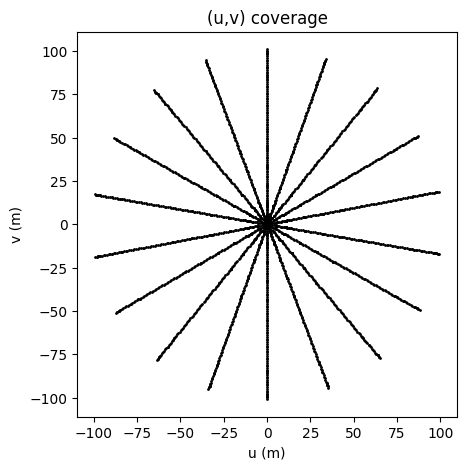

In [3]:
import matplotlib.pyplot as plt

data = read_data('../data/Gaussian_elong.fits')
print(f"{data['nbl']} baselines, {data['ncl']} closure triangles, {data['nlam']} wavelength(s): {data['lam']*1e6} um")

u, v = data['uco'][0], data['vco'][0]
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(u, v, 'k.', ms=2); ax.plot(-u, -v, 'k.', ms=2)
ax.set_xlabel('u (m)'); ax.set_ylabel('v (m)'); ax.set_aspect('equal'); ax.set_title('(u,v) coverage')
plt.show()